In [44]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import pandas as pd
import numpy as np
import json
import random
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import IncrementalPCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor, XGBClassifier

from src.splitting import split_estratificado_autor
from src.utils import df_features_to_numpy, df_target_to_numpy
from src.features import generar_embeddings_pca, entrenar_pca_para_texto
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.graficos import plot_learning_curves_xgboost_regression, plot_feature_importance_xgb

# Cargo el dataset ya procesado

In [46]:
#otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
#tardo aprox 3min14s en correr
K = 10_000
sample = []

with open("goodreads_us_english_primer_filtrado.json", encoding="utf8") as f:
    for i, line in enumerate(f):
        obj = json.loads(line)

        if i < K:
            sample.append(obj)
        else:
            j = random.randint(0, i)
            if j < K:
                sample[j] = obj

df = pd.DataFrame(sample)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: comentario de clara para clara: descomentar este bloque antes de correr

In [ ]:
#otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
#tardo aprox 3min14s en correr
K = 10_000
sample = []

with open("set_train_1.json", encoding="utf8") as f:
    for i, line in enumerate(f):
        obj = json.loads(line)

        if i < K:
            sample.append(obj)
        else:
            j = random.randint(0, i)
            if j < K:
                sample[j] = obj

df = pd.DataFrame(sample)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: lo hago apra cargar el de set de train --> clari, no se si te sirve o no, podemso comentarlo

## Temporal, sacar cuando este el json ya procesado posta

In [47]:
#TEMPORAL: normalmente estas features ya van a estar agrupadas
from src.features import normalize_format
#Le aplico la funcion para reagrupar:
if "format_group" not in df.columns:
    df["format_group"] = df["format"].apply(normalize_format)

print(df["format_group"].value_counts())

format_group
PAPERBACK    5425
HARDCOVER    2226
EBOOK        1737
UNKNOWN       397
AUDIO         147
OTHER          62
COMIC           6
Name: count, dtype: int64


In [48]:
#TEMPORAL: normalmente los generos ya van a estar definidos
from src.features import extraer_generos_libro
df["genres"] = df["popular_shelves"].apply(extraer_generos_libro)

In [49]:
#TEMPORAL: ya va a estar hecho el one hot de estas features
from src.features import multi_binarizer_format, multi_binarizer_genre, one_hot_format
#df = multi_binarizer_format(df) #multi binarizer de format
df = one_hot_format(df)
df = multi_binarizer_genre(df) #multi binarizer de genero

In [50]:
def extraer_autor_principal(autores_sin_preprocesar):
    """
    autores_sin preprocesar: [{authorId, role}, {authorid, role})]
    Asumimos que el primer elemento de la lista es el autor principal (orden tipico de Goodreads)
    """
    # Buscar el primero con role vacío; si no hay, usar el primero de la lista
    for dic_autores in autores_sin_preprocesar:
        if dic_autores["role"] == "":
            return dic_autores["author_id"]
    return autores_sin_preprocesar[0]["author_id"]

df = df[df["authors"].apply(len) > 0]
df["author_id_principal"] = df["authors"].apply(extraer_autor_principal)

In [51]:
df_train, df_val, df_test = split_estratificado_autor(df, test_size=0.15, val_size=0.15)

print(f"Train: {len(df_train)} ({len(df_train)/len(df):.1%})")
print(f"Val: {len(df_val)} ({len(df_val)/len(df):.1%})")
print(f"Test: {len(df_test)} ({len(df_test)/len(df):.1%})")

#Verificacion: distribución de estrellas en cada split
for nombre, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"\n{nombre}:")
    print(d["estrellas"].value_counts(normalize=True).sort_index())

Train: 7211 (72.1%)
Val: 1272 (12.7%)
Test: 1517 (15.2%)

train:
estrellas
0    0.002635
1    0.001109
2    0.006934
3    0.143392
4    0.778533
5    0.067397
Name: proportion, dtype: float64

val:
estrellas
0    0.002358
1    0.000786
2    0.007075
3    0.143868
4    0.780660
5    0.065252
Name: proportion, dtype: float64

test:
estrellas
0    0.002637
1    0.000659
2    0.007251
3    0.143045
4    0.776533
5    0.069875
Name: proportion, dtype: float64


# FIN DE TEMPORAL

## Preparacion de los datos

Calculamos el embedding a nuetsras variables "title" y "description":

Observacion: el embedding en si no podria generar data leakage, pero el PCA si, entocnes hay que tener ciudado con como manejamos eso

In [4]:
modelo_embeddings = SentenceTransformer("all-MiniLM-L6-v2") #Genera embeddings de 384 dimensiones
#Entrenamos el PCA solo con el set de train
descripcion_pca = entrenar_pca_para_texto(df_train["description"], modelo_embeddings, componentes_conservar = 50)
print("termino 1")
#Ahora comenzamos a transformar las variables de los diferentes sets:
#Set de entrenamiento:
descripcion_emb_train = generar_embeddings_pca(df_train["description"], modelo_embeddings, descripcion_pca)
print("termino 2")
#Set de validacion:
descripcion_emb_val = generar_embeddings_pca(df_val["description"], modelo_embeddings, descripcion_pca)
print("Termino 3")
#Set de testeo:
#descripcion_emb_test = generar_embeddings_pca(df_test["description"], modelo_embeddings, descripcion_pca)
#Creo las columnas para el dataset:
descripcion_colum = [f"description_emb_{num}" for num in range(50)]
#Para el de train:
descripcion_emb_train_df = pd.DataFrame(descripcion_emb_train, columns = descripcion_colum, index = df_train.index)
df_train = df_train.join(descripcion_emb_train_df)
#Para el de val:
descripcion_emb_val_df = pd.DataFrame(descripcion_emb_val, columns = descripcion_colum, index = df_val.index)
df_val = df_val.join(descripcion_emb_val_df)
#Para el de test:
#descripcion_emb_test_df = pd.DataFrame(descripcion_emb_test, columns = descripcion_colum, index = set_test_modelo_avanzado_fb.index)
#set_test_modelo_avanzado_fb = set_test_modelo_avanzado_fb.join(descripcion_emb_test_df)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8298.21it/s]


NameError: name 'df_train' is not defined

In [53]:
#Entrenamos el PCA solo con el set de train
titulo_pca = entrenar_pca_para_texto(df_train["title"], modelo_embeddings, componentes_conservar = 20)
#Ahora comenzamos a transformar las variables de los diferentes sets:
#Set de entrenamiento:
titulo_emb_train = generar_embeddings_pca(df_train["title"], modelo_embeddings, titulo_pca)
#Set de validacion:
titulo_emb_val = generar_embeddings_pca(df_val["title"], modelo_embeddings, titulo_pca)
#Set de testeo:
#titulo_emb_test = generar_embeddings_pca(df_test["title"], modelo_embeddings, titulo_pca)

In [54]:
#Creo las columnas para el dataset:
titulo_colum = [f"title_emb_{num}" for num in range(20)]
#Para el de train:
titulo_emb_train_df = pd.DataFrame(titulo_emb_train, columns = titulo_colum, index = df_train.index)
df_train = df_train.join(titulo_emb_train_df)
#Para el de val:
titulo_emb_val_df = pd.DataFrame(titulo_emb_val, columns = titulo_colum, index = df_val.index)
df_val = df_val.join(titulo_emb_val_df)
#Para el de test:
#titulo_emb_test_df = pd.DataFrame(titulo_emb_test, columns = titulo_colum, index = set_test_modelo_avanzado_fb.index)
#df_test = df_test.join(titulo_emb_test_df)

In [55]:
df_train.drop(columns = ["description", "title"], inplace=True)
df_val.drop(columns = ["description", "title"], inplace=True)
#df_test.drop(columns = ["description", "title"], inplace=True)

In [ ]:
import pandas as pd

pd.set_option('display.max_columns', None)
#print(df_train.head())
df_train = df_train.drop(columns = ["text_reviews_count", "language_code", "popular_shelves", "similar_books", 
                         "ratings_count", "authors", "publisher", "format_group", "genres"])
df_val = df_val.drop(columns = ["text_reviews_count", "language_code", "popular_shelves", "similar_books", 
                       "ratings_count", "authors", "publisher", "format_group", "genres"])

In [ ]:
#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
df_train = df_train.drop(columns = ["average_rating", "estrellas"])
df_val = df_val.drop(columns = ["average_rating", "estrellas"])
#TODO: hacerlo tb para test

X_train = df_train.to_numpy()
X_val = df_val.to_numpy()
#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
#TODO: escalar el X_test

### ¿Qué hacemos con la variable "author_id_principal"?

Aunque esta feature es numerica, no tendriamos que considerarla como una variable numerica, sino mas bien como un identificador. Porque hay que evitar que si un author tiene un ID 100 y el otro 55, que los modelos crean que el autor con ID 100 es "mas grande" que el que tiene un numero de ID menor.

Entonces, para solucionar esto, se nos ocurrieron dos posibles opciones (podemos usar sola una o ambas):

* Un target encoding --> para cada autor calculamos, usando solo el set de entrenamiento (para evitar data leakage), su rating promedio (conjutno de sus libros disponibles en nuestro dataset)

    Pero, en vez de usar el clasico, vamos a usar el smoothed target encoding. La idea es que un autor con un solo libro y rating 5 no debería considerarse automaticamente mejor que otro con muchos libros y un promedio de 4.3. Entonces, el suavizado hace que las categorias con pocos ejemplos se acerquen al promedio global, mientras que las categorías con muchas observaciones conservan prácticamente su promedio real.

* Hacer un frecuency encoding --> basicamente es la misma idea que el target encoding, pero, en vez del promedio, la idea es calcualr o la cantidad de libros del autor (cuantas veces aparece)

In [ ]:
def crear_codificador_categorico(X_entrenamiento, y_entrenamiento, columnas_categoricas, tipo_target, smoothing = 20):
    #Aca vamos a guardar toda la info de la codificación
    codificador = {}
    #Calculamos la media global de la variable objetivo (util para usarlo como valor de respaldo para posibles 
    #categorías que aparezcan en val o test, pero no hayan estado en train)
    #Imputariamos con la media y no con la mediana porque, al trabajar con target encoding, 
    #queremos estimar E[target | author], y su mejor estimacion es la media.
    media_global_target = y_entrenamiento.mean()
    
    #Recorremos cada columna categórica que queremos codificar:
    for columna in columnas_categoricas:
        datos_temporales = pd.DataFrame({columna: X_entrenamiento[columna], f"{tipo_target}": y_entrenamiento})
        #Primero hacemos la codifcacion por media del target (ej: promedio del rating de la autora)
        estadisticas = (datos_temporales.groupby(columna)[f"{tipo_target}"].agg(["mean", "count"]))
        media_suavizada = (estadisticas["count"] * estadisticas["mean"] + smoothing * media_global_target) / (estadisticas["count"] + smoothing)
        mapa_media = media_suavizada.to_dict()
        #Ahora, hacemos la codifcacion de frecuencia (ej: cantidad de libros por publisher)
        mapa_frecuencia = datos_temporales[columna].value_counts().to_dict()
        codificador[columna] = {"media": mapa_media, "frecuencia": mapa_frecuencia, "media_global": media_global_target}
    
    return codificador

def transformar_features_categoricas(X_datos, codificador):
    X_transformado = X_datos.copy()
    
    #Recorremos cada columna que fue codificada:
    for columna in codificador.keys():
        #Primero hacemos la codifcacion por media del target:
        X_transformado[f"{columna}_media"] = (X_transformado[columna].map(codificador[columna]["media"]).fillna(codificador[columna]["media_global"]))
        #Ahora, hacemos la codifcacion de frecuencia:
        X_transformado[f"{columna}_frecuencia"] = (X_transformado[columna].map(codificador[columna]["frecuencia"]).fillna(0))
        
    return X_transformado

### ¿Qué hacemos con la variable "publisher"?

Las estrategias que podriamos aplicar en este caso son muy similares a las que pensamos para "author_id_principal": podemos calcular el rating promedio de los publishers o su frecuencia de aparicion (cantidad de libros que lo poseen como valor).

Un one hot encoding no creo que sea la mejor opcion ya que, al tener varios unqiue_value, esto implicaria la generacion de muchas columnas, aumentando la cantidad de parametros en los modelos, consumiendo mucha RAM (el cual es nuestro principal problema). Tampoco creo que sea conveniente un labelencoder porque puede suceder lo que queriamos evitar con los IDs de los autores: que el modelo interprete los numeros como si hubiera un orden (mayor a menor).

In [ ]:
#Lo aplico para los casos de regresion:
columnas_categor = ["author", "publisher"]
codificador_regresion = crear_codificador_categorico(X_train_scaled, y_train_regresion, "average_rating", columnas_categor)
X_train_regresion = transformar_features_categoricas(X_train_scaled, codificador_regresion)
X_val_regresion = transformar_features_categoricas(X_val_scaled,codificador_regresion)
#X_test_regresion = transformar_features_categoricas(X_test_scaled, codificador_regresion)
X_train_regresion = X_train_regresion.drop(columns = columnas_categor)
X_val_regresion = X_val_regresion.drop(columns = columnas_categor)
#X_test_regresion = X_test_regresion.drop(columns = columnas_categor)

In [ ]:
#Ahora para los de clasificacion:
codificador_clasificacion = crear_codificador_categorico(X_train_scaled, y_train_clasificacion, "estrellas", columnas_categor)
X_train_clasificacion = transformar_features_categoricas(X_train_scaled, codificador_clasificacion)
X_val_clasificacion = transformar_features_categoricas(X_val_scaled, codificador_clasificacion)
#X_test_clasificacion = transformar_features_categoricas(X_test_scaled, codificador_clasificacion)
X_train_clasificacion = X_train_clasificacion.drop(columns = columnas_categor)
X_val_clasificacion = X_val_clasificacion.drop(columns = columnas_categor)
#X_test_clasificacion = X_test_clasificacion.drop(columns = columnas_categor)

## Random Forest con features avanzadas - Regresion

## Random Forest con features avanzadas - Clasificacion

## XGBoost con features avanzadas - Regresion

In [ ]:
parametros_grid_search_xgb = {"n_estimators": [100, 200, 300], "max_depth": [3, 5, 7], "learning_rate": [0.01, 0.05, 0.1], "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0]}
idx = np.random.choice(len(X_train_scaled), size = 50_000, replace = False)
X_sub = X_train_scaled[idx]
y_sub_regresion = y_train_regresion[idx]
XGBoostGridSearchRegresion = XGBRegressor(random_state = 42)
grid = GridSearchCV(estimator = XGBoostGridSearchRegresion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "r2", n_jobs = -1, verbose = 2)
grid.fit(X_sub, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

In [ ]:
modeloXGBoostRegresion = XGBRegressor(**mejores_parametros, objective = "reg:squarederror", random_state = 42)
modeloXGBoostRegresion.fit(X_train_scaled, y_train_regresion)

y_pred_train_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_train_scaled)
y_pred_val_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloXGBoostRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloXGBoostRegresion, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))
plot_learning_curves_xgboost_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, **mejores_parametros)

In [ ]:
feature_names = df_train.columns.tolist()
importancias_coef_xgb_reg = pd.DataFrame({"feature": feature_names, "importance": modeloXGBoostRegresion.feature_importances_})
importancias_coef_xgb_reg = importancias_coef_xgb_reg.sort_values("importance", ascending=False)
plot_feature_importance_xgb(importancias_coef_xgb_reg, "para Regresion")

## XGBoost con features avanzadas - Clasificacion

## Red neuronal con features avanzadas - Regresion

PyTorch: 100%|██████████| 100/100 [01:36<00:00,  1.03epoca/s, epoch=100]


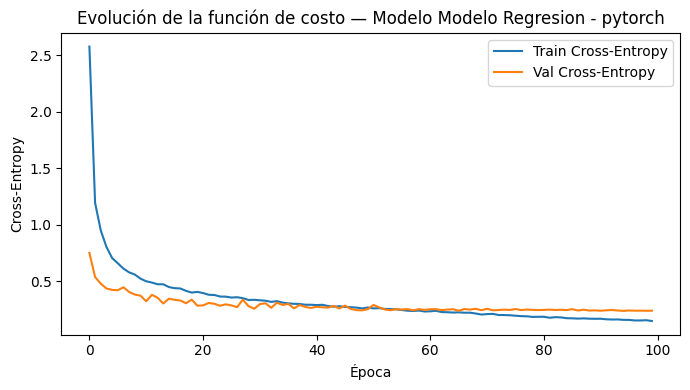

         Train  Validation
MSE   0.087521    0.243125
RMSE  0.295839    0.493077
MAE   0.220315    0.345442
R²    0.643653   -0.024176


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import numpy as np

from src.modelos import MLP_regresion, MLP_clasificacion
from src.utils import run_experiment_pytorch_regresion
from src.metricas import tabla_metricas

if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"

X_train_scaled = X_train_scaled.astype(np.float32)
X_val_scaled = X_val_scaled.astype(np.float32)

modelo_regresion = MLP_regresion(input_size = X_train_scaled.shape[1], hidden_layers = [128, 64], activation = nn.ReLU, dropout = 0.2).to(device)
metricas_train, metricas_val = run_experiment_pytorch_regresion(modelo_regresion, "Modelo Regresion", X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, device)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))